Definir melhor os objs

In [60]:
# Célula 1 · instalar as ferramentas (corre uma vez; precisa de Internet)
!pip install -q pystac-client planetary-computer odc-stac geopandas rasterio shapely
print("Instalação concluída.")

Instalação concluída.


**Chamar as ferramentas**

O que faz: instalar não basta; é preciso chamá-las pelo nome. Comparação: tirar as ferramentas do armário e pô-las em cima da mesa. As principais: numpy (contas com tabelas de números), matplotlib (desenhar), pystac_client (procurar imagens) e odc.stac (descarregar).

In [61]:
# Célula 2 · chamar as ferramentas
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from shapely.geometry import Polygon, mapping
import planetary_computer as pc
from pystac_client import Client
from odc.stac import load

try:
    import google.colab
    print("Ambiente: Google Colab")
except ImportError:
    print("Ambiente: Jupyter local (fora do Colab)")

print("Ferramentas prontas.")

Ambiente: Google Colab
Ferramentas prontas.


**Escolher as datas ✏️**

***O que faz:*** diz quando queremos as imagens: uma da seca e outra da cheia, e quanta nuvem aceitamos. Comparação: pedir a um estafeta “duas fotografias desta zona, uma de julho e outra de fevereiro, só com céu limpo”.

***O que mudar:*** as duas datas e MAX_NUVENS (20 = no máximo 20 % do céu com nuvens). As datas abaixo são exemplos: use as da lista de eventos S1-09. O Sentinel-2 só existe desde 2015.

In [62]:
# Célula 3 · escolher as datas (PARTE EDITÁVEL)
SECA_INICIO,  SECA_FIM  = "2025-07-01", "2025-08-31"   # época seca (troque pelas datas susceptiveis a seca)
CHEIA_INICIO, CHEIA_FIM = "2026-02-01", "2026-03-15"   # cheia (troque pelas datas susceptiveis a cheia)
MAX_NUVENS = 20                                          # % máxima de nuvens

print(f"Seca : {SECA_INICIO} a {SECA_FIM}")
print(f"Cheia: {CHEIA_INICIO} a {CHEIA_FIM}")
print(f"Máximo de nuvens aceite: {MAX_NUVENS} %")

Seca : 2025-07-01 a 2025-08-31
Cheia: 2026-02-01 a 2026-03-15
Máximo de nuvens aceite: 20 %


**Definir a área de estudo (AOI)**

***O que faz:*** define onde olhar: um retângulo à volta do Rio Incomáti, em Marracuene (cerca de 20 km × 27 km), com 4 cantos (longitude, latitude), como um endereço feito de números. O 5.º ponto repete o 1.º para “fechar” a forma.

***Porquê:*** se descarregássemos o satélite todo, demoraria horas. É como recortar com tesoura só o bairro que nos interessa.

Limites da AOI [oeste, sul, leste, norte]: [32.5782, -25.912, 32.776, -25.6677]


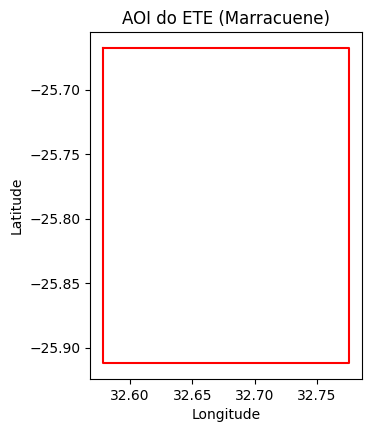

In [63]:
# Célula 4 · definir a AOI do ETE: (longitude, latitude)
geom = Polygon([
    (32.578193171411186, -25.667719151558273),
    (32.775965704920395, -25.667719151558273),
    (32.775965704920395, -25.91196845209879),
    (32.578193171411186, -25.91196845209879),
    (32.578193171411186, -25.667719151558273),
])
bbox = list(geom.bounds)      # [oeste, sul, leste, norte]
print("Limites da AOI [oeste, sul, leste, norte]:", [round(v, 4) for v in bbox])

x, y = geom.exterior.xy
plt.figure(figsize=(3.5, 4.5))
plt.plot(x, y, "r-")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("AOI do ETE (Marracuene)")
plt.show()

***Ligar ao catálogo***

O que faz: liga ao Planetary Computer, um arquivo gratuito da Microsoft com milhares de imagens de satélite. Comparação: entrar numa biblioteca e chegar ao balcão; ainda não pedimos nenhum livro.

In [64]:
# Célula 5 · ligar ao catálogo
catalogo = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)
print("Ligado ao catálogo.")

Ligado ao catálogo.


**Criar a função melhor_dia()**

***O que faz:*** cria uma receita reutilizável. Quando a chamarmos com duas datas, ela: (1) pergunta ao catálogo pelas imagens que cobrem a AOI com poucas nuvens; (2) agrupa as “folhas” do satélite por dia; (3) mostra a % de nuvens de cada dia; (4) escolhe o dia mais limpo.

***Porquê uma função:*** vamos precisar da mesma receita duas vezes (seca e cheia). Escrevê-la uma só vez evita repetir código. ***Comparação:*** uma receita de bolo que se pode fazer em dois dias diferentes.

In [65]:
# Célula 6 · criar a função melhor_dia(): procura imagens e escolhe o dia com menos nuvens
def melhor_dia(inicio, fim):
    busca = catalogo.search(
        collections=["sentinel-2-l2a"],
        intersects=mapping(geom),
        datetime=f"{inicio}/{fim}",
        query={"eo:cloud_cover": {"lt": MAX_NUVENS}},
    )
    itens = list(busca.items())
    print("Imagens encontradas:", len(itens))
    if not itens:
        raise ValueError("Sem imagens entre " + inicio + " e " + fim +
                         ". Aumente o intervalo de datas ou MAX_NUVENS (Célula 3).")

    por_dia = defaultdict(list)
    for i in itens:
        por_dia[i.datetime.date()].append(i)

    def nuvens_do_dia(d):
        return float(np.mean([i.properties["eo:cloud_cover"] for i in por_dia[d]]))

    print("Dias disponíveis e nuvens:")
    for d in sorted(por_dia):
        print(f"  {d}  ->  {nuvens_do_dia(d):.1f} %")

    dia = min(por_dia, key=nuvens_do_dia)
    print("Data escolhida:", dia, "| folhas:", len(por_dia[dia]))
    return dia, por_dia[dia]

print("Função melhor_dia() pronta.")

Função melhor_dia() pronta.


**Criar a função descarregar()**

**O que faz:** outra receita reutilizável. Traz só a AOI, a 10 m, com 5 bandas:

**Banda__________________Luz_________________Para que serve**

  (B02 e B04)-------(Azul e vermelho)------(Com o verde, formam a cor natural)


  (B03)-----------------(Verde)--------------(NDWI e MNDWI)

  (B08)---------------(Infravermelho)--------(próximo (NIR)	(NDWI))

  (B11)----------------(Infravermelho de onda curta)---((SWIR)	MNDWI)


Depois converte os números brutos (0 a 10 000) em reflectância (0 a 1), subtraindo 1 000 nas imagens recentes (um acerto do satélite) e marcando os píxeis sem dados como nan (“não é um número”), para não entrarem nas contas.

**Exemplo:** valor bruto 1 600 → (1 600 − 1 000) / 10 000 = 0,06. A água devolveu só 6 % da luz verde.

In [66]:
# Célula 7 · criar a função descarregar(): traz a AOI, a 10 m, e converte para reflectância
def descarregar(escolhidos):
    ds = load(escolhidos, bands=["B02", "B03", "B04", "B08", "B11"],
              bbox=bbox, crs="EPSG:32736", resolution=10, groupby="solar_day")
    print(f"Descarregado: {ds.sizes['y']} linhas x {ds.sizes['x']} colunas")

    baseline = float(escolhidos[0].properties.get("s2:processing_baseline", "0"))
    desloc = 1000 if baseline >= 4.0 else 0

    def refl(banda):
        dn = ds[banda].isel(time=0).values.astype("float32")
        r = (dn - desloc) / 10000
        r[dn == 0] = np.nan          # píxeis sem dados
        return np.clip(r, 0, 1)

    return {"azul": refl("B02"), "verde": refl("B03"), "vermelho": refl("B04"),
            "nir": refl("B08"), "swir": refl("B11")}

print("Função descarregar() pronta.")

Função descarregar() pronta.


**Descarregar a imagem da seca**

**O que faz:** usa as duas receitas: escolhe o melhor dia da época seca e descarrega-o. O resultado fica na variável seca, que guarda as 5 bandas.

**O que vai ver:** demora 1 a 3 minutos. A lista de dias com nuvens, a data escolhida e Descarregado: 2711 linhas x 1991 colunas (cerca de 5 milhões de píxeis).

In [67]:
# Descarregar a imagem da época SECA
print("--- ÉPOCA SECA ---")
dia_seca, itens_seca = melhor_dia(SECA_INICIO, SECA_FIM)
seca = descarregar(itens_seca)
print("Imagem da seca pronta:", seca["verde"].shape)


--- ÉPOCA SECA ---
Imagens encontradas: 18
Dias disponíveis e nuvens:
  2025-07-01  ->  7.6 %
  2025-07-03  ->  1.7 %
  2025-07-06  ->  1.2 %
  2025-07-08  ->  15.4 %
  2025-07-11  ->  0.0 %
  2025-07-15  ->  4.8 %
  2025-07-16  ->  0.0 %
  2025-07-18  ->  1.5 %
  2025-07-21  ->  0.1 %
  2025-07-26  ->  10.1 %
  2025-07-31  ->  0.0 %
  2025-08-04  ->  0.0 %
  2025-08-05  ->  0.0 %
  2025-08-10  ->  0.0 %
  2025-08-12  ->  15.4 %
  2025-08-22  ->  6.3 %
  2025-08-30  ->  0.0 %
Data escolhida: 2025-08-30 | folhas: 1
Descarregado: 2711 linhas x 1991 colunas
Imagem da seca pronta: (2711, 1991)


**Descarregar a imagem da cheia**

***O que fa***z: o mesmo para a cheia, na variável cheia. Depois garante que as duas imagens têm exatamente o mesmo tamanho, porque vamos comparar píxel a píxel (se tivessem tamanhos diferentes, a comparação falharia).


In [68]:
# Célula 9 · descarregar a imagem da CHEIA
print("--- CHEIA ---")
dia_cheia, itens_cheia = melhor_dia(CHEIA_INICIO, CHEIA_FIM)
cheia = descarregar(itens_cheia)

# Garantir que as duas imagens têm exatamente o mesmo tamanho
if seca["verde"].shape != cheia["verde"].shape:
    h = min(seca["verde"].shape[0], cheia["verde"].shape[0])
    w = min(seca["verde"].shape[1], cheia["verde"].shape[1])
    seca  = {k: v[:h, :w] for k, v in seca.items()}
    cheia = {k: v[:h, :w] for k, v in cheia.items()}
    print("As imagens foram acertadas para o mesmo tamanho:", (h, w))

print("Imagem da cheia pronta:", cheia["verde"].shape)

--- CHEIA ---
Imagens encontradas: 5
Dias disponíveis e nuvens:
  2026-02-06  ->  6.3 %
  2026-02-08  ->  0.1 %
  2026-02-13  ->  16.7 %
  2026-02-18  ->  18.4 %
  2026-02-28  ->  0.2 %
Data escolhida: 2026-02-08 | folhas: 1
Descarregado: 2711 linhas x 1991 colunas
Imagem da cheia pronta: (2711, 1991)


**Verificar os valores**

***O que faz:*** mostra, para cada banda, o valor mínimo, o máximo e a percentagem de píxeis sem dados. É uma verificação rápida antes de guardar.

***O que deve ver:*** todos os valores entre 0 e 1. Uma percentagem muito alta de “sem dados” quer dizer que a imagem ficou cortada ou o satélite não cobriu a zona.

In [69]:
# Célula 10 · verificar as imagens (os valores devem estar entre 0 e 1)
for nome_epoca, imagem in [("SECA", seca), ("CHEIA", cheia)]:
    print(f"--- {nome_epoca} ---")
    for banda, valores in imagem.items():
        print(f"  {banda:9s} mínimo {np.nanmin(valores):.2f} | máximo {np.nanmax(valores):.2f}"
              f" | sem dados {100 * np.isnan(valores).mean():.1f} %")

--- SECA ---
  azul      mínimo 0.02 | máximo 0.55 | sem dados 0.0 %
  verde     mínimo 0.02 | máximo 0.60 | sem dados 0.0 %
  vermelho  mínimo 0.02 | máximo 0.87 | sem dados 0.0 %
  nir       mínimo 0.00 | máximo 0.97 | sem dados 0.0 %
  swir      mínimo 0.00 | máximo 0.92 | sem dados 0.0 %
--- CHEIA ---
  azul      mínimo 0.00 | máximo 0.88 | sem dados 0.8 %
  verde     mínimo 0.00 | máximo 0.93 | sem dados 0.8 %
  vermelho  mínimo 0.00 | máximo 0.89 | sem dados 0.8 %
  nir       mínimo 0.00 | máximo 1.00 | sem dados 0.8 %
  swir      mínimo 0.00 | máximo 0.78 | sem dados 0.8 %


**Guardar os ficheiros**

**O que faz:** grava as duas imagens em incomati_seca.npz e incomati_cheia.npz e descarrega-os para o seu computador.

**Porquê é essencial:** o Colab esquece tudo quando a sessão fecha. Com os ficheiros, a aula corre mesmo sem Internet. Comparação: tirar fotocópias dos apontamentos e levá-las no bolso.

**O que vai ver: Guardados:** ... e o navegador pode pedir permissão para descarregar os dois ficheiros. Copie-os para um pen drive e para os portáteis dos estudantes.

In [70]:
# Célula 11 · guardar os ficheiros (plano B sem Internet)
np.savez("incomati_seca.npz",  **seca,  data=str(dia_seca))
np.savez("incomati_cheia.npz", **cheia, data=str(dia_cheia))
print("Guardados: incomati_seca.npz e incomati_cheia.npz")

try:
    from google.colab import files
    files.download("incomati_seca.npz")
    files.download("incomati_cheia.npz")
except ImportError:
    pass    # fora do Colab não é preciso

Guardados: incomati_seca.npz e incomati_cheia.npz


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Copiar para o Google Drive**

**O que faz:** copia os dois ficheiros para uma pasta do seu Drive, que não é apagada quando o Colab fecha. Aparece uma janela do Google a pedir autorização. Se não quiser usar o Drive, salte esta célula.

In [71]:
# (opcional) copiar os ficheiros para o Google Drive
import os, shutil
PASTA_DRIVE = "/content/drive/MyDrive/ETE_Workshop1"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    shutil.copy("incomati_seca.npz", PASTA_DRIVE)
    shutil.copy("incomati_cheia.npz", PASTA_DRIVE)
    print("Copiados para o Google Drive:", PASTA_DRIVE)
except ImportError:
    print("Esta célula só funciona no Google Colab. Pode saltá-la.")
except FileNotFoundError:
    print("Faltam os ficheiros .npz. Corra primeiro a Célula 11.")
except Exception as erro:
    print("Não foi possível ligar ao Drive (" + type(erro).__name__ + "). Pode saltar esta célula.")

Mounted at /content/drive
Copiados para o Google Drive: /content/drive/MyDrive/ETE_Workshop1


# **PARTE 2 · Passos 1 e 2: ver o Incomáti**

**Garantir que as imagens existem**

**O que faz:** verifica, por esta ordem: (1) as imagens já estão na memória? Usa-as. (2) Não? Procura incomati_seca.npz e incomati_cheia.npz na pasta do Colab. (3) Também não? Abre uma janela para carregar os dois ficheiros do seu computador (escolha os dois ao mesmo tempo).

Quando é útil: quando o Colab reiniciou e perdeu a memória. Comparação: antes da aula, ver se trouxe as fotografias; se não as tem na mão, vai buscá-las à gaveta.

In [72]:
# Célula 13 · garantir que as imagens da seca e da cheia existem
%matplotlib inline
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

def procurar(prefixo):
    achados = []
    for pasta in ["/content", os.getcwd()]:
        achados += glob.glob(os.path.join(pasta, f"incomati_{prefixo}*.npz"))
    return max(achados, key=os.path.getmtime) if achados else None

def ler(caminho):
    z = np.load(caminho)
    return {k: z[k] for k in ("azul", "verde", "vermelho", "nir", "swir")}, str(z["data"])

if "seca" in globals() and "cheia" in globals():
    data_seca  = str(globals().get("dia_seca", ""))
    data_cheia = str(globals().get("dia_cheia", ""))
    print("As imagens já estão na memória.")
else:
    ficheiros = {n: procurar(n) for n in ("seca", "cheia")}

    if not all(ficheiros.values()):
        try:
            from google.colab import files
        except ImportError:
            falta = [f"incomati_{n}.npz" for n, c in ficheiros.items() if not c]
            raise FileNotFoundError("Faltam ficheiros: " + ", ".join(falta) +
                                    ". Coloque-os na pasta " + os.getcwd())
        print("Escolha os DOIS ficheiros: incomati_seca.npz e incomati_cheia.npz...")
        files.upload()
        ficheiros = {n: procurar(n) for n in ("seca", "cheia")}

    if not all(ficheiros.values()):
        falta = [f"incomati_{n}.npz" for n, c in ficheiros.items() if not c]
        raise FileNotFoundError("Ainda faltam: " + ", ".join(falta) +
                                ". Corra a célula outra vez e escolha os dois ficheiros.")

    seca,  data_seca  = ler(ficheiros["seca"])
    cheia, data_cheia = ler(ficheiros["cheia"])
    print("Seca  carregada de:", ficheiros["seca"])
    print("Cheia carregada de:", ficheiros["cheia"])

print("Tamanho das imagens (linhas, colunas):", seca["verde"].shape)

As imagens já estão na memória.
Tamanho das imagens (linhas, colunas): (2711, 1991)


**Ver a imagem inteira**

***O que faz:*** mostra a banda verde da seca com números nas margens: linhas à esquerda, colunas em baixo. Para quê: para encontrar o rio e anotar a sua “morada” na imagem, como na batalha naval: linha 1 300, coluna 900.

***O que fazer:*** procure a faixa comprida e sinuosa (o Rio Incomáti) e anote a linha e a coluna de um ponto nela. Manchas muito brancas são nuvens.

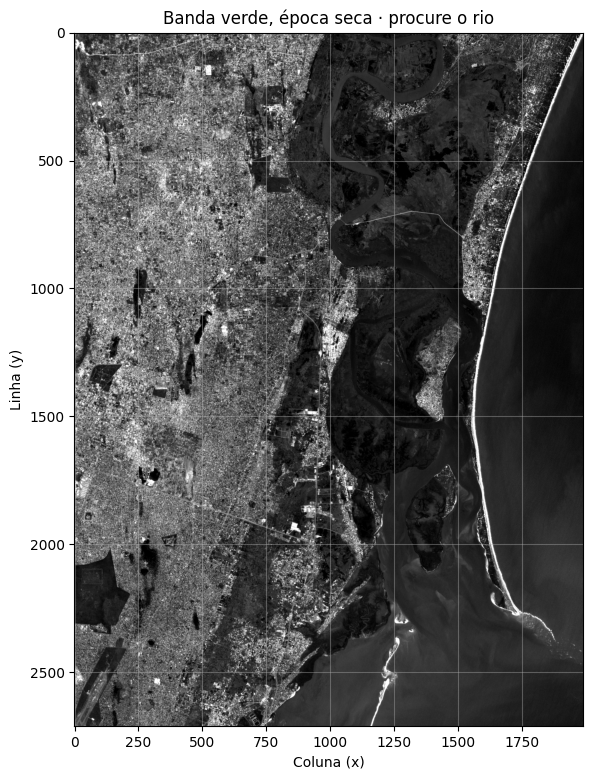

In [73]:
# Célula 14 · ver a imagem inteira, com os números das linhas e colunas
verde_seca = seca["verde"]
vmin, vmax = np.nanpercentile(verde_seca, [1, 99])

plt.figure(figsize=(7, 9))
plt.imshow(verde_seca, cmap="gray", vmin=vmin, vmax=vmax)
plt.grid(True, alpha=0.4)
plt.xlabel("Coluna (x)")
plt.ylabel("Linha (y)")
plt.title("Banda verde, época seca · procure o rio")
plt.show()

**Escolher a zona e simular o Landsat**

**O que faz, em duas partes:**

Recorte: corta um quadrado de 3 km × 3 km a partir do ponto que anotou.
Simulação: cria a imagem “tipo Landsat” guardando 1 píxel em cada 3, em linhas e colunas. Cada píxel novo cobre 30 m × 30 m.

O que mudar: LINHA_INICIAL e COLUNA_INICIAL, com os números da Célula 14. Se o rio ficar de lado, recue 100 a 150 nos dois números. O programa arredonda para múltiplos de 3 (1 000 vira 999); é normal, para as duas imagens mostrarem a mesma zona.

Comparação: uma grelha de 9 quadradinhos (3 × 3) substituída por um quadrado grande: só sobra uma cor. Nota honesta: é uma simulação; o Landsat verdadeiro funciona de outra forma, mas o efeito sobre o detalhe é parecido.

In [74]:
# Célula 15 · escolher a zona e simular o Landsat (PARTE EDITÁVEL)
LINHA_INICIAL  = 1000     # troque pelo número da linha onde está o rio
COLUNA_INICIAL = 800      # troque pelo número da coluna onde está o rio
TAMANHO        = 300      # recorte de 300 x 300 píxeis (3 km x 3 km)

# Garantir que o recorte cabe na imagem e que os números são múltiplos de 3
linhas, colunas = verde_seca.shape
l0 = min(LINHA_INICIAL,  max(linhas  - TAMANHO, 0))
c0 = min(COLUNA_INICIAL, max(colunas - TAMANHO, 0))
l0 = (l0 // 3) * 3
c0 = (c0 // 3) * 3
t  = (min(TAMANHO, linhas - l0, colunas - c0) // 3) * 3

# Simular o Landsat: guardar 1 píxel em cada 3, em linhas e colunas
verde_30m = verde_seca[::3, ::3]

recorte_10m = verde_seca[l0:l0 + t, c0:c0 + t]
recorte_30m = verde_30m[l0 // 3:(l0 + t) // 3, c0 // 3:(c0 + t) // 3]

print(f"Recorte: linhas {l0} a {l0 + t}, colunas {c0} a {c0 + t} ({t * 10 / 1000:.1f} km de lado)")

Recorte: linhas 999 a 1299, colunas 798 a 1098 (3.0 km de lado)


**Comparar 10 m e 30 m**

***O que faz: *** mostra a mesma zona duas vezes: à esquerda com píxeis de 10 m (Sentinel-2, nítida); à direita com píxeis de 30 m (tipo Landsat, aos quadrados), na mesma escala de cinzentos.

 *qual mostra melhor os campos pequenos? E as margens do rio? Que pormenor desapareceu na imagem da direita?*

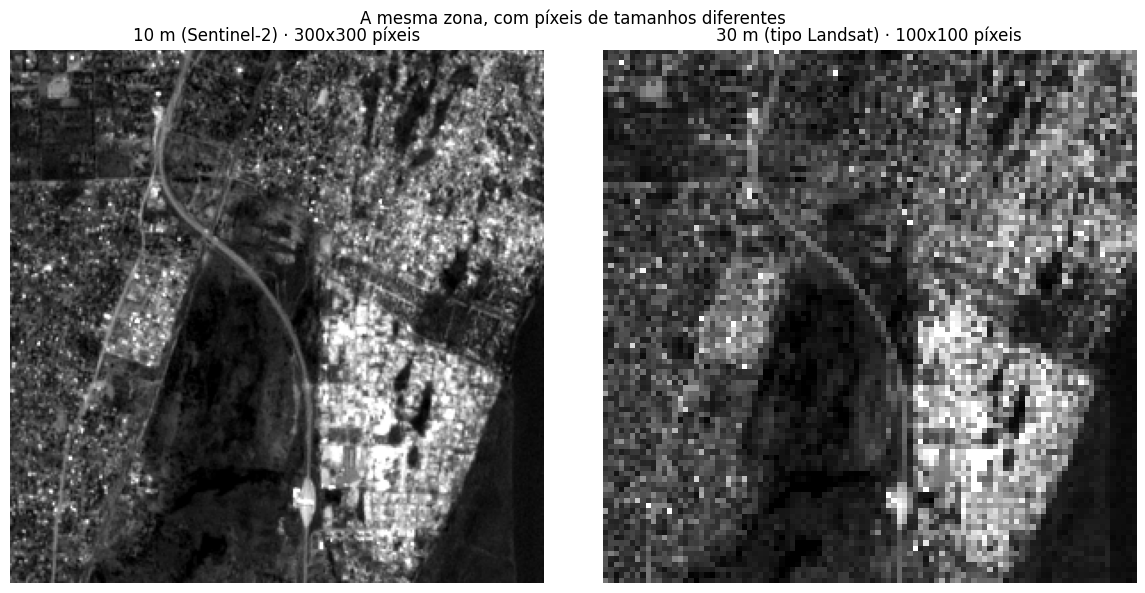

In [75]:
# Célula 16 · desenhar as duas imagens lado a lado
vmax = np.nanpercentile(recorte_10m, 99)
vmin = np.nanpercentile(recorte_10m, 1)

fig, eixos = plt.subplots(1, 2, figsize=(12, 6))
eixos[0].imshow(recorte_10m, cmap="gray", vmin=vmin, vmax=vmax)
eixos[0].set_title(f"10 m (Sentinel-2) · {recorte_10m.shape[0]}x{recorte_10m.shape[1]} píxeis")
eixos[1].imshow(recorte_30m, cmap="gray", vmin=vmin, vmax=vmax)
eixos[1].set_title(f"30 m (tipo Landsat) · {recorte_30m.shape[0]}x{recorte_30m.shape[1]} píxeis")
for e in eixos:
    e.axis("off")
plt.suptitle("A mesma zona, com píxeis de tamanhos diferentes")
plt.tight_layout()
plt.show()

**Contar os píxeis**

***O que faz:*** conta os píxeis de cada imagem. Na zona de 3 km × 3 km: 90 000 a 10 m e 10 000 a 30 m. Como 900 m² ÷ 100 m² = 9, o Sentinel-2 tem 9 vezes mais píxeis. Um campo de futebol (cerca de 7 000 m²) tem 70 píxeis no Sentinel-2 e apenas 8 no Landsat.

*para mapear uma cheia de 2013, que satélite usamos? (O Landsat, porque o Sentinel-2 só existe desde 201*5.)

In [76]:
# Célula 17 · contar os píxeis e comparar
n10 = recorte_10m.size
n30 = recorte_30m.size
print(f"Zona de {t * 10 / 1000:.1f} km x {t * 10 / 1000:.1f} km")
print(f"Píxeis a 10 m: {n10}  (cada um cobre 100 m²)")
print(f"Píxeis a 30 m: {n30}  (cada um cobre 900 m²)")
print(f"O Sentinel-2 tem {n10 / n30:.0f} vezes mais píxeis na mesma zona.")

Zona de 3.0 km x 3.0 km
Píxeis a 10 m: 90000  (cada um cobre 100 m²)
Píxeis a 30 m: 10000  (cada um cobre 900 m²)
O Sentinel-2 tem 9 vezes mais píxeis na mesma zona.


**Comparar o rio na seca e na cheia**

**O que faz:** junta as bandas vermelho, verde e azul para criar a imagem em cor natural, como a veríamos de cima, e mostra a seca e a cheia lado a lado.
**Comparação:** duas fotografias do mesmo quintal, antes e depois da chuva forte.

*onde acham que vai haver mais água na cheia? (Isto é “prever”)*

***Depois de correr:*** cada par escreve uma frase a dizer o que mudou (por exemplo, “na cheia, o rio alargou e cobriu campos junto à margem”). Se houver nuvens a tapar o rio, volte à Célula 3 e escolha outra data.

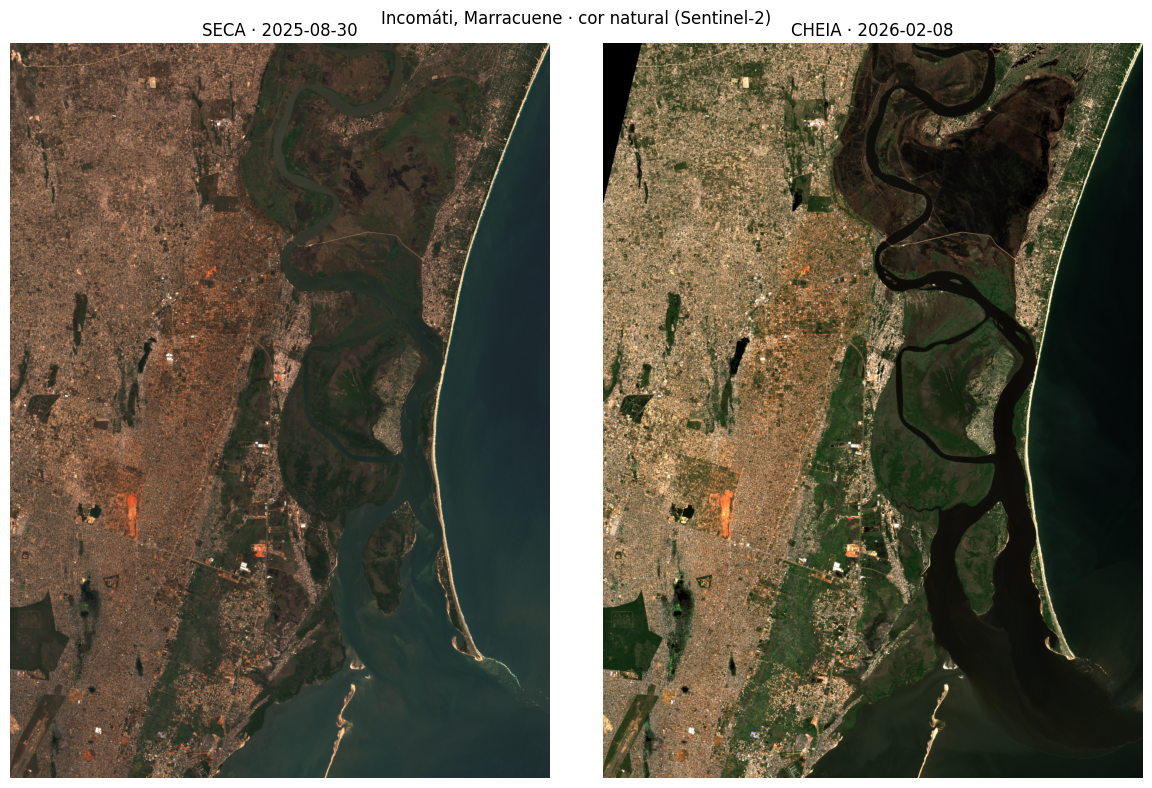

In [77]:
# Célula 18 · comparar o rio na seca e na cheia (cor natural)
def cor_natural(b):
    rgb = np.dstack([b["vermelho"], b["verde"], b["azul"]])
    return np.clip(np.nan_to_num(rgb) / 0.3, 0, 1)

fig, eixos = plt.subplots(1, 2, figsize=(12, 8))
eixos[0].imshow(cor_natural(seca));  eixos[0].set_title(f"SECA · {data_seca}")
eixos[1].imshow(cor_natural(cheia)); eixos[1].set_title(f"CHEIA · {data_cheia}")
for e in eixos:
    e.axis("off")
plt.suptitle("Incomáti, Marracuene · cor natural (Sentinel-2)")
plt.tight_layout()
plt.show()

# **PARTE 3 · Passo 3: o NDWI, o MNDWI e o limiar**

**Calcular o NDWI e o MNDWI**

***O que faz:*** aplica duas fórmulas a todos os píxeis ao mesmo tempo, para a seca e para a cheia:

NDWI = (Verde − NIR) / (Verde + NIR)
MNDWI = (Verde − SWIR) / (Verde + SWIR)

***Porquê funciona:*** a água reflete mais luz verde do que infravermelho, por isso o resultado fica positivo. A vegetação e o solo fazem o contrário, e o resultado fica negativo. O MNDWI usa o SWIR no lugar do NIR e separa melhor a água das zonas construídas e do solo escuro.

In [78]:
# Célula 19 · calcular o NDWI e o MNDWI (seca e cheia)
def indices(b):
    with np.errstate(divide="ignore", invalid="ignore"):
        ndwi  = (b["verde"] - b["nir"])  / (b["verde"] + b["nir"])     # verde contra infravermelho próximo
        mndwi = (b["verde"] - b["swir"]) / (b["verde"] + b["swir"])    # verde contra infravermelho de onda curta
    return ndwi, mndwi

ndwi_seca,  mndwi_seca  = indices(seca)
ndwi_cheia, mndwi_cheia = indices(cheia)

for nome, valores in [("NDWI  seca ", ndwi_seca),  ("NDWI  cheia", ndwi_cheia),
                      ("MNDWI seca ", mndwi_seca), ("MNDWI cheia", mndwi_cheia)]:
    print(f"{nome}: mínimo {np.nanmin(valores):+.2f} | máximo {np.nanmax(valores):+.2f}")

NDWI  seca : mínimo -0.81 | máximo +0.84
NDWI  cheia: mínimo -1.00 | máximo +1.00
MNDWI seca : mínimo -0.83 | máximo +0.90
MNDWI cheia: mínimo -1.00 | máximo +0.90


**Ver os mapas dos índices**

**O que faz:** desenha 4 mapas: NDWI e MNDWI, na seca e na cheia. Como ler as cores: 🔵 azul = valor alto, provável água; 🟡🔴 amarelo e vermelho = valor baixo, vegetação ou solo.

**Perguntas:** onde aparece mais azul, na seca ou na cheia? O MNDWI mostra o rio mais “limpo” do que o NDWI? Aparece azul na vila ou em sombras?

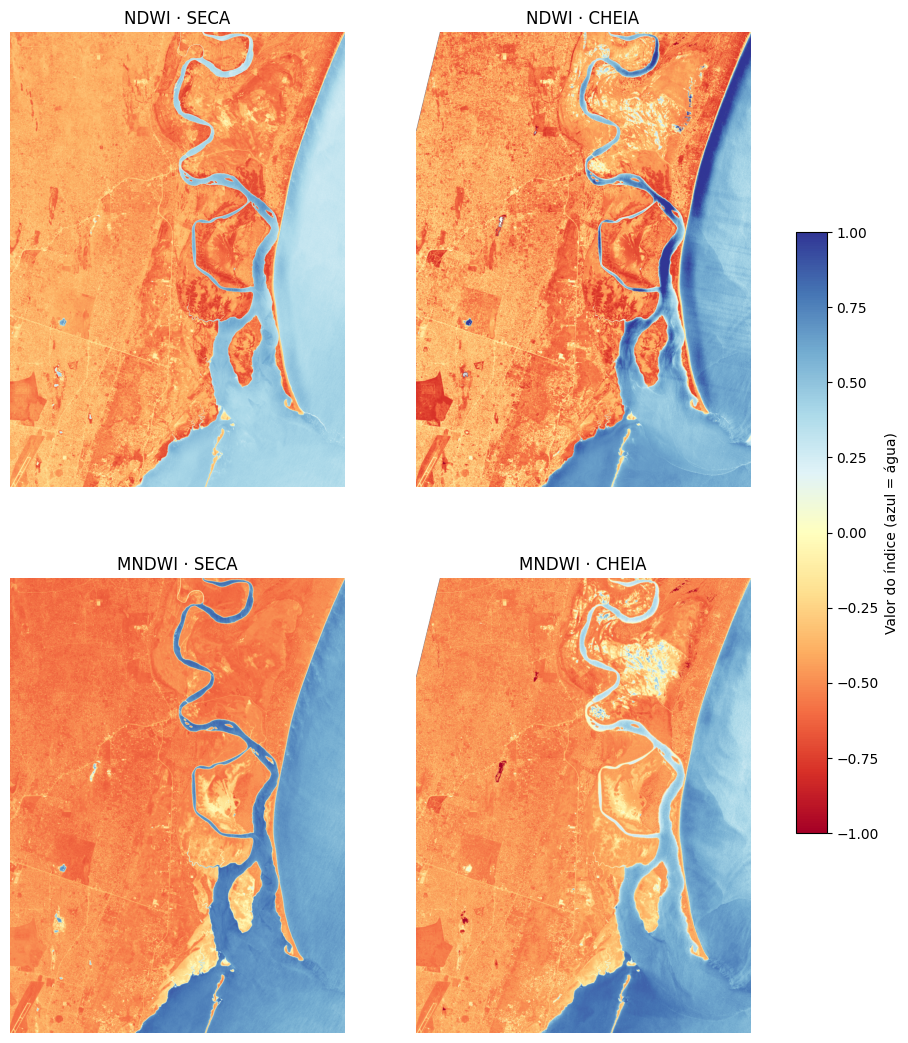

In [79]:
# Célula 20 · ver os mapas dos índices
fig, eixos = plt.subplots(2, 2, figsize=(12, 13))
mapas = [(ndwi_seca,  "NDWI · SECA"),  (ndwi_cheia,  "NDWI · CHEIA"),
         (mndwi_seca, "MNDWI · SECA"), (mndwi_cheia, "MNDWI · CHEIA")]
for e, (m, titulo) in zip(eixos.ravel(), mapas):
    im = e.imshow(m, cmap="RdYlBu", vmin=-1, vmax=1)
    e.set_title(titulo)
    e.axis("off")
fig.colorbar(im, ax=eixos, shrink=0.6, label="Valor do índice (azul = água)")
plt.show()

# **Testar limiares**

***O que faz:*** transforma o índice (números contínuos) num mapa de sim ou não: “este píxel é água?” Se o índice for maior que o limiar, é água. Mostra 3 mapas lado a lado e a área de água em hectares de cada um.

***O ponto central:*** o 0 é só um ponto de partida. Não existe um limiar único certo; depende do local.

***Analogia da peneira:*** buracos grandes demais (limiar baixo) deixam passar o que não devia (aparece “água” em sombras e na vila); buracos pequenos demais (limiar alto) retêm o que devia passar (falta água nas margens). O analista escolhe o tamanho certo para o local.

***O que mudar:*** INDICE ("NDWI" ou "MNDWI"), EPOCA ("seca" ou "cheia") e a lista LIMIARES.

**Pergunta de reflexão: um píxel junto ao rio, na cheia, tem NDWI = 0,05. É água? Resposta: depende do limiar**.

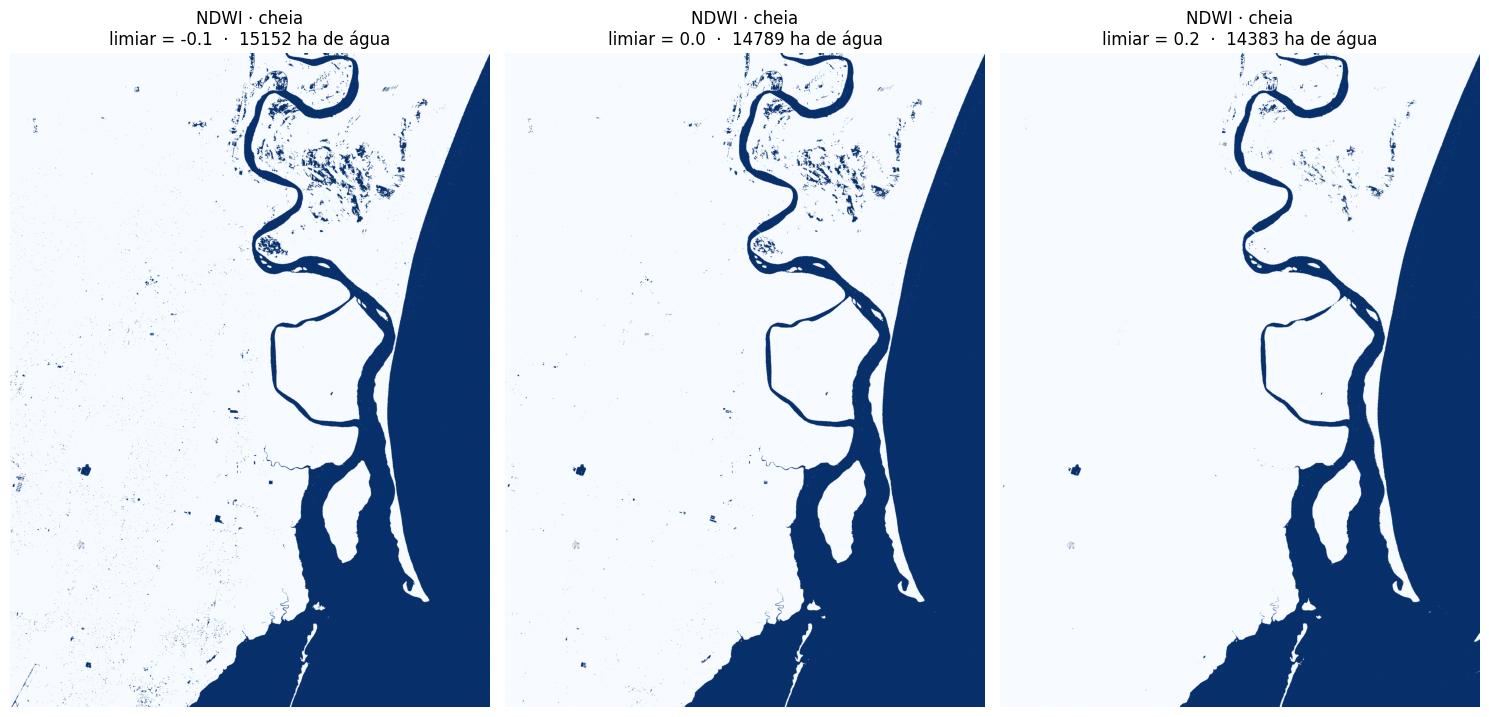

In [80]:
# Célula 21 · testar limiares (PARTE EDITÁVEL)
INDICE   = "NDWI"            # "NDWI" ou "MNDWI"
EPOCA    = "cheia"           # "seca" ou "cheia"
LIMIARES = [-0.1, 0.0, 0.2]  # troque os valores e volte a correr

tabela = {("NDWI", "seca"): ndwi_seca,   ("NDWI", "cheia"): ndwi_cheia,
          ("MNDWI", "seca"): mndwi_seca, ("MNDWI", "cheia"): mndwi_cheia}
chave = (INDICE.upper(), EPOCA.lower())
if chave not in tabela:
    raise ValueError('INDICE deve ser "NDWI" ou "MNDWI" e EPOCA deve ser "seca" ou "cheia".')
indice = tabela[chave]

fig, eixos = plt.subplots(1, len(LIMIARES), figsize=(5 * len(LIMIARES), 7), squeeze=False)
for e, lim in zip(eixos[0], LIMIARES):
    agua = indice > lim                          # verdadeiro onde o índice é maior que o limiar
    area_ha = agua.sum() * 100 / 10000           # cada píxel = 100 m²; 1 ha = 10 000 m²
    e.imshow(agua, cmap="Blues")
    e.set_title(f"{chave[0]} · {chave[1]}\nlimiar = {lim}  ·  {area_ha:.0f} ha de água")
    e.axis("off")
plt.tight_layout()
plt.show()

**Histograma: onde pôr o limiar?**

**O que faz:** desenha um gráfico que conta quantos píxeis têm cada valor do índice, e marca com linhas vermelhas os limiares que testou. Serve para justificar a escolha com dados.

**Como ler:** o eixo horizontal é o valor do índice; o vertical é o número de píxeis (em escala logarítmica, para se ver também o grupo pequeno). Costuma haver dois grupos: um grande, de terra (valores negativos) e um mais pequeno, de água (valores positivos). Um bom limiar fica no vale entre os dois grupos.

**Comparação:** contar quantos alunos tiraram cada nota. Se há dois grupos (os que estudaram e os que não), a nota de passagem faz sentido entre os dois.

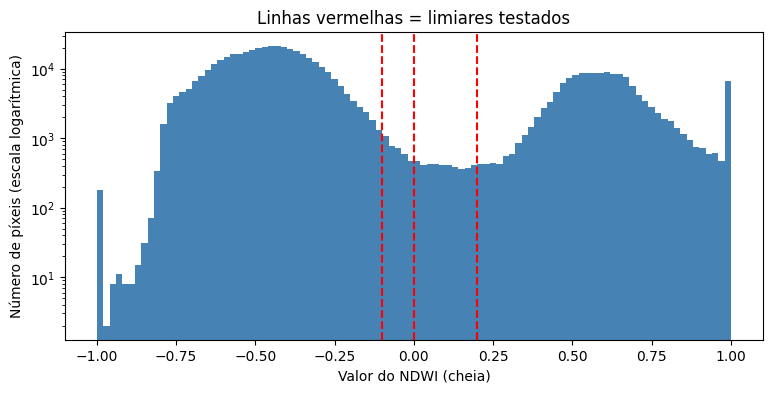

In [81]:
# Célula 22 · histograma: onde pôr o limiar?
valores = indice[~np.isnan(indice)][::10]        # 1 em cada 10, para ser rápido

plt.figure(figsize=(9, 4))
plt.hist(valores, bins=100, color="steelblue")
plt.yscale("log")
for lim in LIMIARES:
    plt.axvline(lim, color="red", linestyle="--")
plt.xlabel(f"Valor do {chave[0]} ({chave[1]})")
plt.ylabel("Número de píxeis (escala logarítmica)")
plt.title("Linhas vermelhas = limiares testados")
plt.show()

# **PARTE 4 · Passo 4: o mapa de água final**

**O mapa de água do par**

***O que faz:***

Usa o índice e o limiar escolhidos pelo.
Cria o mapa de água da seca e da cheia lado a lado (azul = água), com título, o nome do par e a justificação escrita por baixo.
Guarda a imagem num ficheiro PNG e, no Colab, descarrega-a.
Calcula a área de água em hectares nas duas épocas e a diferença.

O que cada par edita: NOME_PAR, INDICE_FINAL, LIMIAR_FINAL e JUSTIFICACAO (uma frase sua, baseada no que viu nos mapas e no histograma).

Exemplo da conta: 5 000 píxeis de água × 100 m² = 500 000 m² = 50 hectares (cerca de 70 campos de futebol).

Para a apresentação (3 minutos por par), diga:

O índice e o limiar que escolheu.
Porquê (a sua justificação).
Quanto aumentou a água da seca para a cheia.

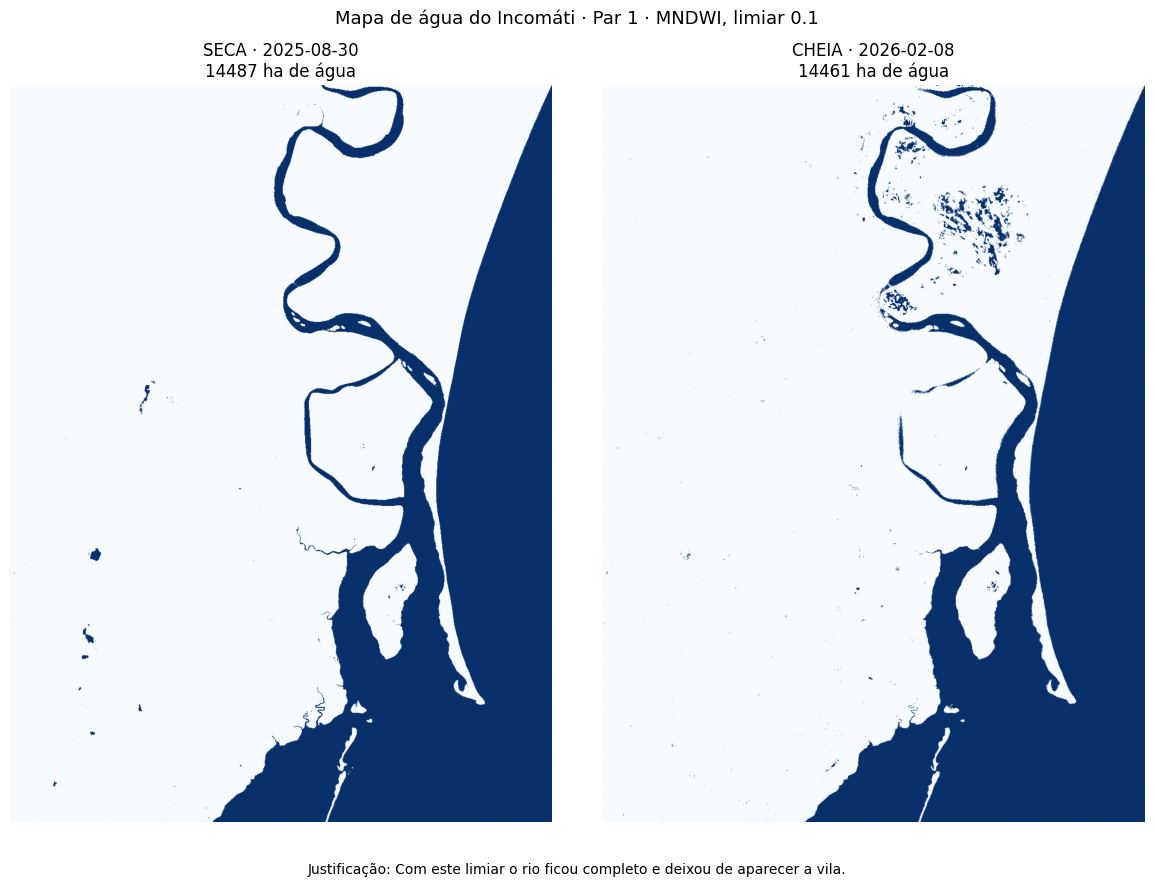

Mapa guardado: mapa_agua_Par_1.png
Área de água na seca : 14487 ha
Área de água na cheia: 14461 ha
Diferença            : -26 ha
Na cheia há 1.0 vezes a área de água da seca.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:
# Célula 23 · o mapa de água final do par (PARTE EDITÁVEL)
NOME_PAR     = "Par 1"
INDICE_FINAL = "MNDWI"       # "NDWI" ou "MNDWI"
LIMIAR_FINAL = 0.1           # o limiar que o par escolheu
JUSTIFICACAO = "Com este limiar o rio ficou completo e deixou de aparecer a vila."   # escreva a sua

import textwrap

tabela_final = {"NDWI": (ndwi_seca, ndwi_cheia), "MNDWI": (mndwi_seca, mndwi_cheia)}
if INDICE_FINAL.upper() not in tabela_final:
    raise ValueError('INDICE_FINAL deve ser "NDWI" ou "MNDWI".')
ind_seca, ind_cheia = tabela_final[INDICE_FINAL.upper()]

agua_seca  = ind_seca  > LIMIAR_FINAL
agua_cheia = ind_cheia > LIMIAR_FINAL
ha_seca  = agua_seca.sum()  * 100 / 10000
ha_cheia = agua_cheia.sum() * 100 / 10000

fig, eixos = plt.subplots(1, 2, figsize=(12, 9))
eixos[0].imshow(agua_seca,  cmap="Blues")
eixos[0].set_title(f"SECA · {data_seca}\n{ha_seca:.0f} ha de água")
eixos[1].imshow(agua_cheia, cmap="Blues")
eixos[1].set_title(f"CHEIA · {data_cheia}\n{ha_cheia:.0f} ha de água")
for e in eixos:
    e.axis("off")
fig.suptitle(f"Mapa de água do Incomáti · {NOME_PAR} · {INDICE_FINAL.upper()}, limiar {LIMIAR_FINAL}",
             fontsize=13)
fig.text(0.5, 0.02, textwrap.fill("Justificação: " + JUSTIFICACAO, 110), ha="center", fontsize=10)
plt.tight_layout(rect=[0, 0.06, 1, 0.95])

ficheiro = f"mapa_agua_{NOME_PAR.replace(' ', '_')}.png"
plt.savefig(ficheiro, dpi=150, bbox_inches="tight")
plt.show()

print("Mapa guardado:", ficheiro)
print(f"Área de água na seca : {ha_seca:.0f} ha")
print(f"Área de água na cheia: {ha_cheia:.0f} ha")
print(f"Diferença            : {ha_cheia - ha_seca:+.0f} ha")
if ha_seca > 0:
    print(f"Na cheia há {ha_cheia / ha_seca:.1f} vezes a área de água da seca.")

try:
    from google.colab import files
    files.download(ficheiro)
except ImportError:
    pass    # fora do Colab não é preciso